# Google Earth Engine (GEE) to `Geocroissant` 🥐

<img src="../assets/geocr.jpg" alt="GeoCroissant" width="150" style="float: right; margin-left: 20px;" />

## Overview

This notebook converts **Google Earth Engine (GEE)** image assets into **GeoCroissant** format.


## 1. Initialize Earth Engine

We initialize the Earth Engine Python client with the registered project `code-earthengine`.


In [1]:
#!pip install earthengine-api mlcroissant rasterio requests numpy torch matplotlib pillow

import json
import io
import requests
import numpy as np
import matplotlib.pyplot as plt
import torch
import rasterio
from rasterio.io import MemoryFile
import mlcroissant as mlc
import ee
from rasterio.io import MemoryFile
from rasterio.plot import show

/home/xuan/miniconda3/envs/dl/lib/python3.11/site-packages/google/api_core/_python_version_support.py:273: FutureWarning: You are using a Python version (3.11.6) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [2]:
# Initialize Earth Engine
ee.Initialize(project="code-earthengine")
token = ee.data.get_persistent_credentials().token

## 2. Verify Asset Metadata via REST API

We query the Earth Engine REST endpoint for the asset using the bearer token and project header (`x-goog-user-project: code-earthengine`).


In [3]:
asset_id = "COPERNICUS/S2/20170430T190351_20170430T190351_T10SEG"
rest_url = f"https://earthengine.googleapis.com/v1alpha/projects/earthengine-public/assets/{asset_id}"

headers = {
    "Authorization": f"Bearer {token}",
    "x-goog-user-project": "code-earthengine",
}

response = requests.get(rest_url, headers=headers)
print(f"REST API Status: {response.status_code}")
rest_meta = response.json()
print("Asset ID:   ", rest_meta.get("id"))
print("Total Bands:", len(rest_meta.get("bands", [])))

REST API Status: 200
Asset ID:    COPERNICUS/S2/20170430T190351_20170430T190351_T10SEG
Total Bands: 16


## 3. Retrieve and Curate Asset Bands

We retrieve full metadata with `ee.data.getAsset(asset_id)` and inspect all 16 bands.


In [4]:
meta = ee.data.getAsset(asset_id)
props = meta["properties"]
bands_list = meta["bands"]

print("Bands:", [b["id"] for b in bands_list])

coords = meta["geometry"]["coordinates"][0]
lons = [c[0] for c in coords]
lats = [c[1] for c in coords]
bbox_str = f"{min(lats):.6f} {min(lons):.6f} {max(lats):.6f} {max(lons):.6f}"

crs_code = bands_list[0]["grid"]["crsCode"]
min_spatial_res = min(
    abs(b["grid"]["affineTransform"]["scaleX"])
    for b in bands_list
    if "affineTransform" in b.get("grid", {})
)

print(f"CRS:             {crs_code}")
print(f"Bounding Box:    {bbox_str}")
print(f"Spatial Res:     {min_spatial_res}m")
print(f"MGRS Tile:       {props.get('MGRS_TILE')}")
print(f"Acquisition:     {meta['startTime']}")

Bands: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B10', 'B11', 'B12', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']
CRS:             EPSG:32610
Bounding Box:    36.951572 -123.000342 37.947680 -121.750759
Spatial Res:     10m
MGRS Tile:       10SEG
Acquisition:     2017-04-30T19:04:11.415Z


## 4. Define GeoCroissant Metadata with `mlcroissant`

In [5]:
ctx = mlc.Context(
    is_live_dataset=True,
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/geo/",
        "http://mlcommons.org/croissant/RAI/",
    ],
)

# Sentinel-2 MSI optical band wavelengths and bandwidths (nm)
S2_OPTICAL_BANDS = {
    "B1": {"cw": 443.0, "bw": 27.0},
    "B2": {"cw": 490.0, "bw": 98.0},
    "B3": {"cw": 560.0, "bw": 45.0},
    "B4": {"cw": 665.0, "bw": 38.0},
    "B5": {"cw": 705.0, "bw": 19.0},
    "B6": {"cw": 740.0, "bw": 18.0},
    "B7": {"cw": 783.0, "bw": 28.0},
    "B8": {"cw": 842.0, "bw": 145.0},
    "B8A": {"cw": 865.0, "bw": 33.0},
    "B9": {"cw": 940.0, "bw": 26.0},
    "B10": {"cw": 1375.0, "bw": 30.0},
    "B11": {"cw": 1610.0, "bw": 143.0},
    "B12": {"cw": 2190.0, "bw": 242.0},
}

# 1. Optical spectral bands
spectral_bands = [
    mlc.SpectralBand(
        name=b["id"],
        center_wavelength=mlc.QuantitativeValue(
            value=S2_OPTICAL_BANDS[b["id"]]["cw"], unitText="nm"
        ),
        bandwidth=mlc.QuantitativeValue(
            value=S2_OPTICAL_BANDS[b["id"]]["bw"], unitText="nm"
        ),
    )
    for b in bands_list
    if b["id"] in S2_OPTICAL_BANDS
]

# 2. FileObjects for asset REST endpoint and per-band remote assets
distribution = [
    mlc.FileObject(
        ctx=ctx,
        id="gee-s2-asset-endpoint",
        name="asset-metadata",
        description=f"Google Earth Engine REST endpoint for {asset_id}",
        content_url=rest_url,
        encoding_formats=["application/json"],
    )
]

for b in bands_list:
    b_id = b["id"]
    res_val = abs(b.get("grid", {}).get("affineTransform", {}).get("scaleX", 10))
    distribution.append(
        mlc.FileObject(
            ctx=ctx,
            id=f"gee-s2-band-{b_id.lower()}",
            name=f"{b_id}.tif",
            description=(
                f"Sentinel-2 band {b_id} for asset {asset_id} at {res_val}m resolution"
            ),
            content_url=f"{rest_url}/{b_id}",
            encoding_formats=["image/tiff"],
        )
    )

# 3. RecordSet containing scene metadata and band URLs
record_fields = [
    mlc.Field(id="scenes/scene_id", name="scene_id", data_types=[mlc.DataType.TEXT]),
    mlc.Field(id="scenes/datetime", name="datetime", data_types=[mlc.DataType.DATE]),
    mlc.Field(id="scenes/mgrs_tile", name="mgrs_tile", data_types=[mlc.DataType.TEXT]),
    mlc.Field(
        id="scenes/cloud_cover", name="cloud_cover", data_types=[mlc.DataType.FLOAT]
    ),
    mlc.Field(id="scenes/epsg", name="epsg", data_types=[mlc.DataType.INTEGER]),
    mlc.Field(
        id="scenes/ee_asset_url", name="ee_asset_url", data_types=[mlc.DataType.URL]
    ),
]

scene_data = {
    "scenes/scene_id": asset_id,
    "scenes/datetime": meta["startTime"],
    "scenes/mgrs_tile": props.get("MGRS_TILE", "10SEG"),
    "scenes/cloud_cover": float(props.get("CLOUDY_PIXEL_PERCENTAGE", 0.0)),
    "scenes/epsg": int(crs_code.split(":")[-1]),
    "scenes/ee_asset_url": rest_url,
}

for b in bands_list:
    b_id = b["id"]
    col_id = f"scenes/{b_id.lower()}_url"
    record_fields.append(
        mlc.Field(id=col_id, name=f"{b_id.lower()}_url", data_types=[mlc.DataType.URL])
    )
    scene_data[col_id] = f"{rest_url}/{b_id}"

scenes_recordset = mlc.RecordSet(
    id="scenes",
    name="scenes",
    description=f"Sentinel-2 Level-1C scene records for {asset_id} with all 16 bands",
    data=[scene_data],
    fields=record_fields,
)

# 4. Metadata object
metadata = mlc.Metadata(
    ctx=ctx,
    name="gee-sentinel-2-t10seg",
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/geo/",
        "http://mlcommons.org/croissant/RAI/",
    ],
    description=(
        "Sentinel-2A Level-1C top-of-atmosphere reflectance image over MGRS tile"
        f" {props.get('MGRS_TILE', '10SEG')} acquired on"
        f" {meta['startTime'][:10]} retrieved from Google Earth Engine, converted to"
        " GeoCroissant format."
    ),
    url=rest_url,
    cite_as="""@article{CopernicusSentinel2,
  title={Copernicus Sentinel-2 MSI Level-1C},
  author={European Space Agency},
  year={2017},
  url={https://doi.org/10.5270/S2_-742ikth}}""",
    date_published=meta["startTime"][:10],
    version="1.0.0",
    license=(
        "https://sentinel.esa.int/documents/247904/690755/Sentinel_Data_Legal_Notice"
    ),
    keywords=[
        "google-earth-engine",
        "sentinel-2",
        "copernicus",
        "level-1c",
        "multispectral",
        "mgrs-10seg",
        "remote-sensing",
        "geospatial",
    ],
    creators=[
        mlc.Organization(name="European Space Agency", url="https://www.esa.int/"),
        mlc.Organization(
            name="Google Earth Engine", url="https://earthengine.google.com/"
        ),
    ],
    coordinate_reference_system=crs_code,
    spatial_resolution=mlc.QuantitativeValue(
        value=float(min_spatial_res), unitText="m"
    ),
    record_endpoint=rest_url,
    sampling_strategy=(
        "Single cloud-free acquisition over MGRS tile 10SEG from Earth Engine public"
        " catalog."
    ),
    spatial_bias=(
        "Localized to UTM Zone 10N covering San Francisco Bay Area and coastal"
        " California."
    ),
    band_configuration=mlc.BandConfiguration(
        total_bands=len(bands_list),
        band_names_list=[b["id"] for b in bands_list],
    ),
    spectral_band_metadata=spectral_bands,
    spatial_coverage={
        "@type": "Place",
        "geo": {
            "@type": "GeoShape",
            "box": bbox_str,
        },
    },
    distribution=distribution,
    record_sets=[scenes_recordset],
    extra_properties={"isLiveDataset": True},
)

print(f"GeoCroissant metadata instantiated with {len(bands_list)} bands.")

GeoCroissant metadata instantiated with 16 bands.


## 5. Serialize to JSON-LD

We export the `mlc.Metadata` object to standard JSON-LD and write it to `gee.json`.


In [6]:
metadata_json = metadata.to_json()

output_json = "gee.json"
with open(output_json, "w") as f:
    json.dump(metadata_json, f, indent=2)

print(f"GeoCroissant metadata saved to {output_json}")

GeoCroissant metadata saved to gee.json


## 6. Validate GeoCroissant Metadata

We validate `gee.json` using the `mlcroissant` command-line validator to confirm strict compliance with Croissant 1.1 and GeoCroissant 1.0 specifications.


In [7]:
# Validate using mlcroissant CLI
!mlcroissant validate --jsonld=gee.json

I1107 03:29:38.733264 133579759421248 validate.py:53] Done.


## 7. Visualize Scene


Asset ID from gee.json: COPERNICUS/S2/20170430T190351_20170430T190351_T10SEG


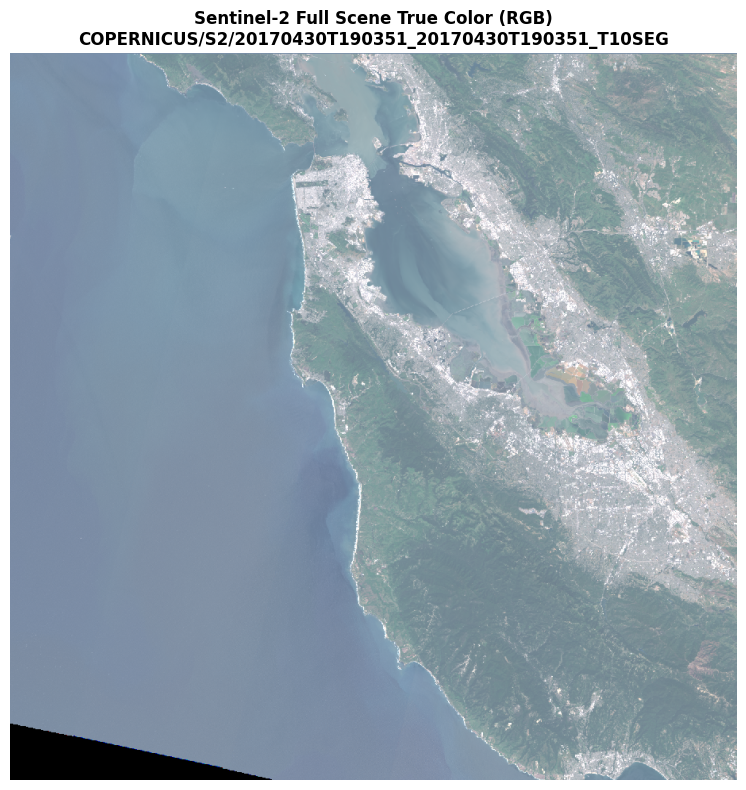

In [8]:
# 1. Load asset ID directly from gee.json
with open("gee.json", "r") as f:
    data = json.load(f)["recordSet"][0]["data"]
    asset_id = (
        data[0]["scenes/scene_id"]
        if isinstance(data, list)
        else data["scenes/scene_id"]
    )

print(f"Asset ID from gee.json: {asset_id}")

# 2. Download actual GeoTIFF for the whole scene (RGB: B4, B3, B2)
url = (
    ee.Image(asset_id)
    .select(["B4", "B3", "B2"])
    .getDownloadURL({"scale": 120, "crs": "EPSG:32610", "format": "GEO_TIFF"})
)

# 3. Read GeoTIFF with rasterio and visualize full scene
with MemoryFile(requests.get(url).content) as memfile:
    with memfile.open() as src:
        rgb = np.clip(src.read().astype(np.float32) / 3000.0, 0, 1)
        fig, ax = plt.subplots(figsize=(8, 8))
        show(rgb, ax=ax, title=f"Sentinel-2 Full Scene True Color (RGB)\n{asset_id}")
        plt.axis("off")
        plt.tight_layout()
        plt.show()